# EDA 05 · Listening logs: quality and scale

**Question.** What do the daily listening counters look like inside the 90-day window, and which cleaning, clipping and transformation do w1 (aggregates) and w2 (daily sequences) need?

**Fields.** `date`, `num_25`, `num_50`, `num_75`, `num_985`, `num_100` (songs played up to 25 %, 50 %, 75 %, 98.5 % and over 98.5 % of their length), `num_unq` (distinct songs), `total_secs`.

**Population and window.** `fit` customers (notebook 00); dates from 2016-11-03 to 2017-01-31. Integrity checks run on **all** fit rows; distribution analyses run on a **random sample of 100,000 fit customers with all their days** (not the first N rows of the file).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl

EDA_DIR = next(p for p in (Path.cwd(), Path.cwd() / "eda") if (p / "_common.py").exists())
sys.path.insert(0, str(EDA_DIR))
import _common as C

pl.Config.set_tbl_rows(30); pl.Config.set_tbl_width_chars(160); pl.Config.set_tbl_cols(12)
pd.options.display.float_format = "{:,.4f}".format
pd.set_option("display.max_colwidth", None)

users = C.load_fit_population()
BASE = users["is_churn"].mean()
COUNTS = ["num_25", "num_50", "num_75", "num_985", "num_100"]

## 1. Which file covers the window?

In [2]:
pd.DataFrame([
    {"file": f, **pl.scan_parquet(C.PARQUET_DIR / f)
        .select(first=pl.col("date").min(), last=pl.col("date").max(), rows=pl.len()).collect().to_dicts()[0]}
    for f in ("user_logs.parquet", "user_logs_v2.parquet")])

,file,first,last,rows
0,user_logs.parquet,20150101,20170228,392106543
1,user_logs_v2.parquet,20170301,20170331,18396362


`user_logs` runs from 2015-01-01 to 2017-02-28; `user_logs_v2` contains **only March 2017**. The February window (Nov–Jan) and the March test window (Dec–Feb) are both covered entirely by the first file. `user_logs_v2` is never used by any feature; the legacy EDA described its distributions, i.e. a month outside every window.

## 2. Integrity on all fit rows in the window

In [3]:
full = C.scan_user_logs(users)
integrity = full.select(
    rows=pl.len(),
    customers=pl.col("msno").n_unique(),
    user_days=pl.struct("msno", "date").n_unique(),
    negative_values=pl.sum_horizontal([(pl.col(c) < 0).sum() for c in C.LOG_COLS]),
    non_finite_secs=(~pl.col("total_secs").is_finite()).sum(),
    secs_over_24h=(pl.col("total_secs") > 86_400).sum(),
    unq_above_plays=(pl.col("num_unq") > pl.sum_horizontal(COUNTS)).sum(),
    zero_activity=(pl.sum_horizontal(COUNTS) == 0).sum(),
).collect(engine="streaming")
integrity

rows,customers,user_days,negative_values,non_finite_secs,secs_over_24h,unq_above_plays,zero_activity
u32,u32,u32,u32,u32,u32,u32,u32
29045271,605922,29045271,0,0,7410,0,0



The window is clean in every structural sense: 29 million rows for 605,922 customers, exactly **one row per customer-day**, no negative values, no non-finite seconds, `num_unq` never exceeds the number of plays, and no row with zero plays (a day without listening simply has no row). The guards in the current pipelines (negatives → 0, non-finite → 0) never fire in this window; they can stay as cheap assertions. The only anomaly is **7,410 customer-days with more than 24 hours of listening** (0.03 %).


## 3. Distributions per customer-day (sample)

In [4]:
sample_users = users.sample(n=100_000, seed=C.SEED)
logs = C.cached("05_logs_sample_raw", lambda: C.scan_user_logs(sample_users).collect(engine="streaming"))
logs = logs.with_columns(plays=pl.sum_horizontal(COUNTS))
print(f"sample customers: {sample_users.height:,} | with logs in the window: {logs['msno'].n_unique():,} | customer-days: {logs.height:,}")
QS = [0.5, 0.9, 0.99, 0.999, 0.9999]
qtab = pd.DataFrame({c: [logs[c].quantile(q) for q in QS] + [logs[c].max()] for c in C.LOG_COLS + ["plays"]},
                    index=[f"p{q*100:g}" for q in QS] + ["max"]).T
qtab

sample customers: 100,000 | with logs in the window: 81,436 | customer-days: 3,900,134


,p50,p90,p99,p99.9,p99.99,max
num_25,2.0000,16.0000,59.0000,142.0000,285.0000,"1,458.0000"
num_50,1.0000,4.0000,14.0000,44.0000,105.0000,485.0000
num_75,0.0000,3.0000,8.0000,18.0000,45.0000,672.0000
num_985,0.0000,3.0000,9.0000,23.0000,85.0000,"2,516.0000"
num_100,17.0000,75.0000,178.0000,329.0000,556.0000,"10,857.0000"
num_unq,19.0000,70.0000,150.0000,234.0000,370.0000,"1,425.0000"
total_secs,"4,668.0630","19,571.8490","43,358.1650","76,962.9520","113,733.9300","2,495,418.8950"
plays,25.0000,97.0000,203.0000,356.0000,631.0000,"11,019.0000"


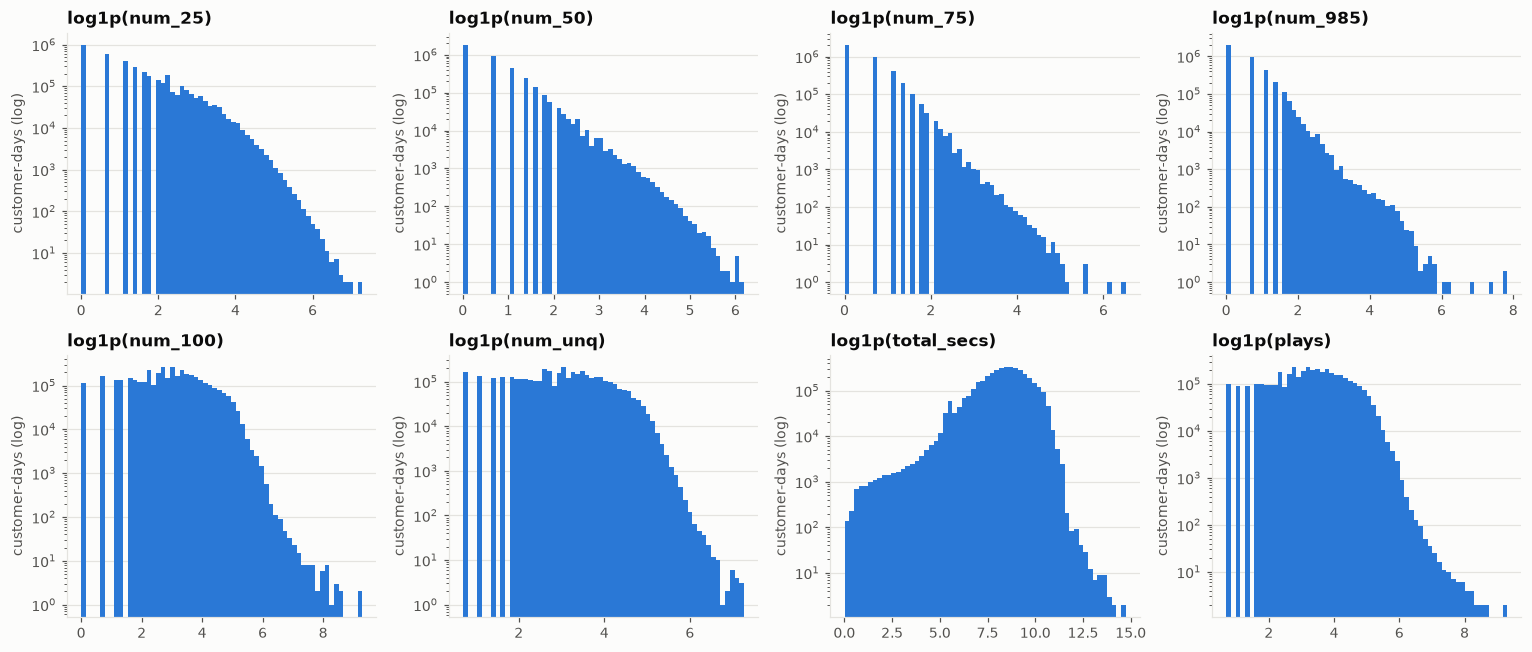

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, c in zip(axes.ravel(), C.LOG_COLS + ["plays"]):
    v = np.log1p(logs[c].to_numpy().astype(float))
    ax.hist(v, bins=60, color=C.COLORS["series"])
    ax.set_title(f"log1p({c})", loc="left"); ax.set_yscale("log"); ax.set_ylabel("customer-days (log)")
fig.tight_layout(); C.save_fig(fig, "05_log1p_distributions"); plt.show()


- Every counter is extremely right-skewed: the median day has 17 complete plays and 2 skips, the maximum has 10,857 and 1,458.
- Full plays (`num_100`) dominate; the middle buckets (`num_50`, `num_75`, `num_985`) are near zero on most days. The legacy "bimodal listening" reading is this: people either skip early or finish the song.
- On a `log1p` scale `num_100`, `num_unq`, `total_secs` and `plays` become compact, near-symmetric distributions; the sparse middle buckets stay zero-inflated. `log1p` is the right scale for both the w2 sequences and any numeric aggregate.


## 4. Plausibility: seconds per play and impossible days

In [6]:
spp = logs.filter(pl.col("plays") > 0).with_columns(secs_per_play=pl.col("total_secs") / pl.col("plays"))
print(spp.select([pl.col("secs_per_play").quantile(q).alias(f"p{q*100:g}") for q in (0.001, 0.01, 0.5, 0.99, 0.999)] +
                 [pl.col("secs_per_play").max().alias("max")]))
over = logs.filter(pl.col("total_secs") > 86_400)
print(f"\ncustomer-days over 24 h: {over.height:,} ({over.height / logs.height:.3%}) "
      f"from {over['msno'].n_unique():,} customers")
print(over.select("total_secs", "plays", "num_100", "num_unq").describe())

shape: (1, 6)
┌──────────┬────────┬────────────┬──────────┬─────────┬────────┐
│ p0.1     ┆ p1     ┆ p50        ┆ p99      ┆ p99.9   ┆ max    │
│ ---      ┆ ---    ┆ ---        ┆ ---      ┆ ---     ┆ ---    │
│ f64      ┆ f64    ┆ f64        ┆ f64      ┆ f64     ┆ f64    │
╞══════════╪════════╪════════════╪══════════╪═════════╪════════╡
│ 2.632333 ┆ 35.028 ┆ 204.664816 ┆ 297.6786 ┆ 607.249 ┆ 5270.0 │
└──────────┴────────┴────────────┴──────────┴─────────┴────────┘

customer-days over 24 h: 1,013 (0.026%) from 477 customers
shape: (9, 5)
┌────────────┬───────────────┬────────────┬────────────┬────────────┐
│ statistic  ┆ total_secs    ┆ plays      ┆ num_100    ┆ num_unq    │
│ ---        ┆ ---           ┆ ---        ┆ ---        ┆ ---        │
│ str        ┆ f64           ┆ f64        ┆ f64        ┆ f64        │
╞════════════╪═══════════════╪════════════╪════════════╪════════════╡
│ count      ┆ 1013.0        ┆ 1013.0     ┆ 1013.0     ┆ 1013.0     │
│ null_count ┆ 0.0           ┆ 0.0   

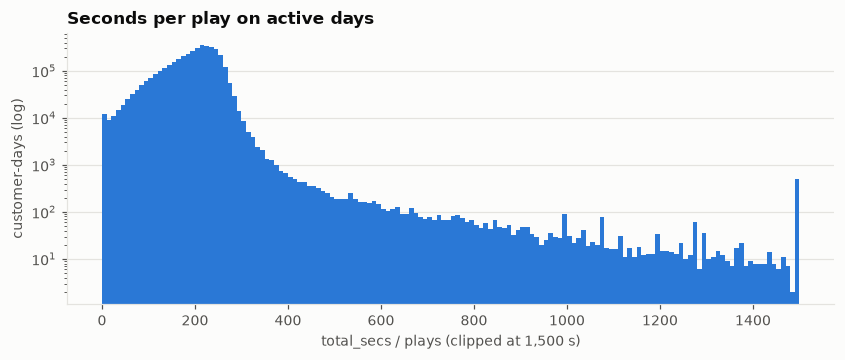

In [7]:
ratio = spp.select(pl.col("secs_per_play").clip(0, 1500)).to_series().to_numpy()
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(ratio, bins=150, color=C.COLORS["series"]); ax.set_yscale("log")
ax.set_xlabel("total_secs / plays (clipped at 1,500 s)"); ax.set_ylabel("customer-days (log)")
ax.set_title("Seconds per play on active days", loc="left")
C.save_fig(fig, "05_secs_per_play"); plt.show()


- On active days a play lasts about 205 seconds at the median (a typical song), and 99.9 % of days stay under 10 minutes per play: the seconds and the counts are consistent with each other.
- Days over 24 hours are not "seconds gone wrong": they also have very large play counts (median 453 plays) at a normal ~220 s per play. Seconds and plays are inflated **together**, as if several days or devices had been merged into one row. Capping only `total_secs` would leave the counts inflated.


## 5. Clipping rule

Two options for the daily values: the current pipelines' **p99.9 per channel** (learned on fit), or a **physical cap** (24 h for `total_secs`). We measure how many customer-days each rule touches and how much it changes each customer's 90-day totals.

In [8]:
p999 = {c: float(logs[c].quantile(0.999)) for c in C.LOG_COLS}
rules = {
    "p99.9 per channel": {c: p999[c] for c in C.LOG_COLS},
    "24 h cap on secs only": {"total_secs": 86_400.0},
}
rows = []
for name, caps in rules.items():
    clipped = logs.with_columns([pl.col(c).clip(upper_bound=v).alias(c) for c, v in caps.items()])
    touched = logs.select(pl.any_horizontal([pl.col(c) > v for c, v in caps.items()]).mean()).item()
    tot_raw = logs.group_by("msno").agg([pl.col(c).sum() for c in caps])
    tot_clip = clipped.group_by("msno").agg([pl.col(c).sum().alias(f"{c}_c") for c in caps])
    j = tot_raw.join(tot_clip, on="msno")
    changed = j.select(pl.any_horizontal([(pl.col(f"{c}_c") < 0.9 * pl.col(c)) for c in caps]).mean()).item()
    rows.append({"rule": name, "customer-days clipped": touched, "customers with a 90-day total cut by > 10 %": changed})
print("p99.9 limits:", {c: round(v, 1) for c, v in p999.items()})
pd.DataFrame(rows)

p99.9 limits: {'num_25': 142.0, 'num_50': 44.0, 'num_75': 18.0, 'num_985': 23.0, 'num_100': 329.0, 'num_unq': 234.0, 'total_secs': 76963.0}


,rule,customer-days clipped,customers with a 90-day total cut by > 10 %
0,p99.9 per channel,0.0049,0.0328
1,24 h cap on secs only,0.0003,0.0012



- The current rule (p99.9 per channel, learned on fit) touches 0.5 % of customer-days but cuts the 90-day total of **3.3 % of customers by more than 10 %**. The p99.9 limits (e.g. 142 skips or 329 full plays a day) are well within what a heavy listener can do, so this rule mostly trims real heavy users.
- The physically motivated rule touches only the impossible days (0.03 %) and changes 0.1 % of customers' totals.
- Proposal: on days with `total_secs > 86,400`, **rescale every channel by 86,400 / total_secs** (keeps the day's mix, removes the impossible volume), then use `log1p`. No per-channel quantile clipping, and therefore no fitted clipping parameters to carry from fit to test.


## 6. How many days are active?

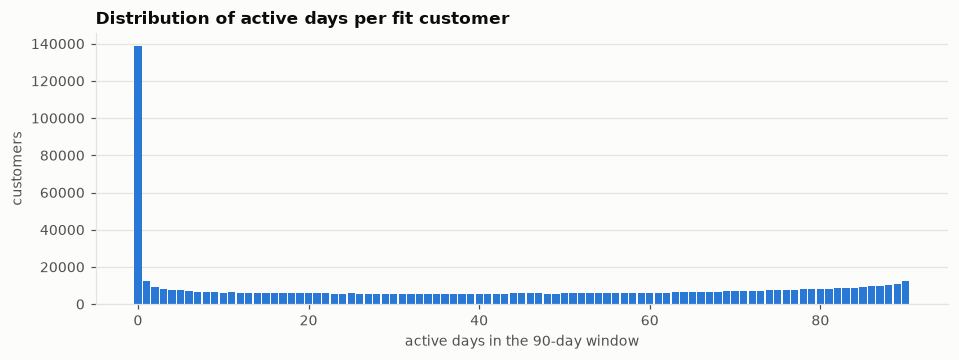

0 days: 18.6% | 1-10: 10.5% | 80-90: 14.2% | median among active: 50


In [9]:
cov = C.cached("00_log_coverage_90d", lambda: (
    C.scan_user_logs(users).group_by("msno")
     .agg(active_days=pl.col("date").n_unique(), last_log=pl.col("date").max()).collect(engine="streaming")))
act = users.join(cov, on="msno", how="left").with_columns(pl.col("active_days").fill_null(0))
counts = act.group_by("active_days").len().sort("active_days").to_pandas()
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(counts["active_days"], counts["len"], width=0.85, color=C.COLORS["series"])
ax.set_xlabel("active days in the 90-day window"); ax.set_ylabel("customers")
ax.set_title("Distribution of active days per fit customer", loc="left")
C.save_fig(fig, "05_active_days"); plt.show()
print(f"0 days: {(act['active_days'] == 0).mean():.1%} | 1-10: {act['active_days'].is_between(1, 10).mean():.1%} | "
      f"80-90: {act['active_days'].is_between(80, 90).mean():.1%} | median among active: {act.filter(pl.col('active_days') > 0)['active_days'].median():.0f}")

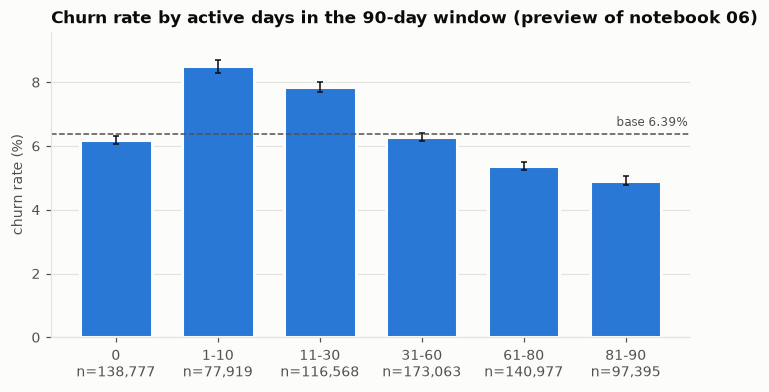

,ad_band,n,churners,churn_rate,ci_low,ci_high,share,lift
0,0,138777,8604,0.0620,0.0607,0.0633,0.1864,0.9699
1,1-10,77919,6621,0.0850,0.0830,0.0870,0.1046,1.3293
2,11-30,116568,9152,0.0785,0.0770,0.0801,0.1565,1.2282
3,31-60,173063,10867,0.0628,0.0617,0.0639,0.2324,0.9823
4,61-80,140977,7579,0.0538,0.0526,0.0550,0.1893,0.8410
5,81-90,97395,4781,0.0491,0.0477,0.0505,0.1308,0.7679


In [10]:
AD_ORDER = ["0", "1-10", "11-30", "31-60", "61-80", "81-90"]
ad = act.with_columns(ad_band=pl.when(pl.col("active_days") == 0).then(pl.lit("0"))
    .when(pl.col("active_days") <= 10).then(pl.lit("1-10")).when(pl.col("active_days") <= 30).then(pl.lit("11-30"))
    .when(pl.col("active_days") <= 60).then(pl.lit("31-60")).when(pl.col("active_days") <= 80).then(pl.lit("61-80"))
    .otherwise(pl.lit("81-90")))
ad_tbl = C.churn_rate_by(ad, "ad_band", order=AD_ORDER)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
C.plot_churn_rate(ad_tbl, "ad_band", ax=ax, base_rate=BASE, title="Churn rate by active days in the 90-day window (preview of notebook 06)")
C.save_fig(fig, "05_active_days_churn"); plt.show()
ad_tbl


- Activity is not bimodal: 18.6 % of fit customers have **no** listening day in the window, and the rest spread almost uniformly from 1 to 90 days, with a mild rise towards daily listeners (14 % at 80–90 days).
- Raw churn moves little with activity: 4.9 % for daily listeners, 8.5 % for 1–10 days, and **6.2 % for customers with no listening at all**, close to the base rate. Silence alone is not a churn signal, because many auto-renew customers keep paying without using the service. Notebook 06 checks whether activity matters *inside* each subscription state.


## 7. Conclusions


The logs are structurally clean in the 90-day window and come entirely from `user_logs.parquet`. The cleaning needed is small: neutralise the few impossible days and use `log1p`. The current p99.9 clipping does more harm than good, because it trims real heavy listeners and adds fitted parameters for no benefit. As a raw signal, activity is weak (4.9–8.5 % churn across all activity levels), which matches the low rank of listening features in the legacy analysis; notebooks 06 and 07 check whether it helps once the subscription state is known.


In [11]:
decisions = C.write_decisions("05", "Listening logs: quality and scale", [
    {"finding": "`user_logs_v2` holds only March 2017; both feature windows (Feb and test) come entirely from `user_logs`",
     "decision": "Feature code reads `user_logs` for the windows; `user_logs_v2` is not needed (keep reading both only if harmless)",
     "kind": "no action"},
    {"finding": "Window is structurally clean: one row per customer-day, no negatives, no non-finite seconds, num_unq <= plays",
     "decision": "Keep the negative / non-finite guards as assertions only",
     "kind": "no action"},
    {"finding": "7,410 customer-days (0.03 %) exceed 24 h, with counts inflated in proportion (~220 s per play)",
     "decision": "On those days rescale all 7 channels by 86,400 / total_secs",
     "kind": "cleaning"},
    {"finding": "p99.9 per-channel clipping trims real heavy listeners (3.3 % of customers lose > 10 % of their 90-day total)",
     "decision": "Drop the fitted p99.9 clipping (`log_clip_p999`) in w1 and any equivalent in w2",
     "kind": "drop"},
    {"finding": "All counters are heavily right-skewed; log1p makes num_100, num_unq, total_secs compact",
     "decision": "Use log1p for every listening channel (w2 sequences) and for numeric listening aggregates in the linear model",
     "kind": "transformation"},
    {"finding": "18.6 % of fit customers have no listening day; churn by activity only ranges 4.9-8.5 % (silent customers 6.2 %)",
     "decision": "Keep `has_listening_logs`; do not treat silence as a risk flag on its own; within-state value tested in notebook 06",
     "kind": "open"},
])
decisions

,finding,decision,kind
0,`user_logs_v2` holds only March 2017; both feature windows (Feb and test) come entirely from `user_logs`,Feature code reads `user_logs` for the windows; `user_logs_v2` is not needed (keep reading both only if harmless),no action
1,"Window is structurally clean: one row per customer-day, no negatives, no non-finite seconds, num_unq <= plays",Keep the negative / non-finite guards as assertions only,no action
2,"7,410 customer-days (0.03 %) exceed 24 h, with counts inflated in proportion (~220 s per play)","On those days rescale all 7 channels by 86,400 / total_secs",cleaning
3,p99.9 per-channel clipping trims real heavy listeners (3.3 % of customers lose > 10 % of their 90-day total),Drop the fitted p99.9 clipping (`log_clip_p999`) in w1 and any equivalent in w2,drop
4,"All counters are heavily right-skewed; log1p makes num_100, num_unq, total_secs compact",Use log1p for every listening channel (w2 sequences) and for numeric listening aggregates in the linear model,transformation
5,18.6 % of fit customers have no listening day; churn by activity only ranges 4.9-8.5 % (silent customers 6.2 %),Keep `has_listening_logs`; do not treat silence as a risk flag on its own; within-state value tested in notebook 06,open


---
**Previous:** `04_transactions_history.ipynb` · **Next:** `06_user_logs_aggregates.ipynb`